# Mock fiber assignment

`mock_fiber_assign` selects a spatially uniform, density-limited subsample of a catalog within a circular field of view. The fibers are spread over a grid in proportion to each cell's area inside the field. Each cell keeps up to its allocation of objects, chosen by priority within the cell. Fibers left over in sparse cells are **not** moved elsewhere. Fiber collisions and patrol radii are not modelled.

This notebook runs it on two mock catalogs:

1. a uniform field, dense everywhere, which uses every fiber;
2. a compact Plummer system, which uses only a small share of the fibers.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from spec5.instrument import mock_fiber_assign

In [2]:
# Spec-S5 focal plane
FOV_DIAMETER_DEG = 1.1
FOV_RADIUS_ARCMIN = FOV_DIAMETER_DEG / 2 * 60
N_FIBERS = 13000

SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
def sample_plummer_2d(n_stars, rhalf, random_state=None):
    """
    Sample 2D projected positions from a Plummer distribution.
    
    Parameters
    ----------
    n_stars : int
        Number of stars to sample
    rhalf : float
        Half-light radius (same units as output x, y)
    random_state : int, optional
        Random seed for reproducibility
    
    Returns
    -------
    x, y : arrays
        2D positions in same units as rhalf
    """
    rng = np.random.default_rng(random_state)
    
    # Sample projected radius from Plummer CDF
    # P(R) = R^2 / (R^2 + a^2), inverting: R = a * sqrt(u) / sqrt(1 - u)
    u = rng.uniform(0, 0.9999, n_stars)  # avoid u=1 (infinite radius)
    R = rhalf * np.sqrt(u) / np.sqrt(1 - u)
    
    # Sample random angles
    theta = rng.uniform(0, 2*np.pi, n_stars)
    
    # Convert to Cartesian coordinates
    x = R * np.cos(theta)
    y = R * np.sin(theta)
    
    return x, y

In [4]:
def plot_assignment(catalog, observed, title, max_points=100_000, seed=0):
    """Plot a random subset of the catalog with the selected targets on top."""
    rng = np.random.default_rng(seed)
    shown = catalog.iloc[rng.permutation(len(catalog))[:max_points]]

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(shown['x'], shown['y'], s=1, c='0.6', lw=0,
               label=f'Catalog ({len(shown):,} of {len(catalog):,} shown)')
    ax.scatter(observed['x'], observed['y'], s=2, c='C3', lw=0,
               label=f'Observed ({len(observed):,})')
    ax.add_patch(plt.Circle((0, 0), FOV_RADIUS_ARCMIN, fill=False, ls='--', color='k'))
    ax.set_xlim(-FOV_RADIUS_ARCMIN * 1.05, FOV_RADIUS_ARCMIN * 1.05)
    ax.set_ylim(-FOV_RADIUS_ARCMIN * 1.05, FOV_RADIUS_ARCMIN * 1.05)
    ax.set_aspect('equal')
    ax.set_xlabel('x [arcmin]')
    ax.set_ylabel('y [arcmin]')
    ax.set_title(title)
    ax.legend(loc='upper right', markerscale=5)
    return fig, ax

## 1. Uniform field

Every grid cell has more objects than fibers, so all 13,000 fibers are used.

12,998 of 13,000 fibers assigned


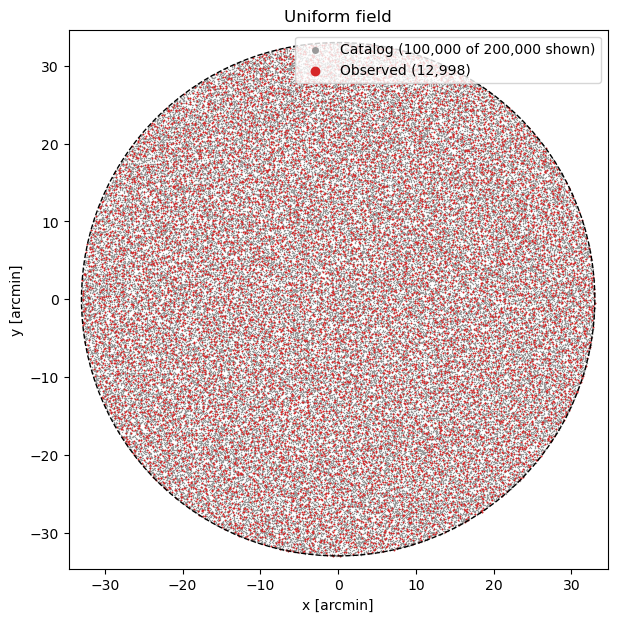

In [5]:
n_uniform = 200_000
r = FOV_RADIUS_ARCMIN * np.sqrt(rng.uniform(0, 1, n_uniform))
theta = rng.uniform(0, 2 * np.pi, n_uniform)
uniform = pd.DataFrame({
    'x': r * np.cos(theta),
    'y': r * np.sin(theta),
    'zmag': rng.uniform(15, 22, n_uniform),
})

uniform_observed = mock_fiber_assign(
    uniform,
    n_fibers=N_FIBERS,
    fov_radius_arcmin=FOV_RADIUS_ARCMIN,
    priority_column='zmag',
    seed=SEED,
)
print(f'{len(uniform_observed):,} of {N_FIBERS:,} fibers assigned')
plot_assignment(uniform, uniform_observed, 'Uniform field');

## 2. Compact Plummer system

With a half-light radius of 0.2′, almost the whole catalog lies within a few grid cells of the centre. Each cell keeps only its share of the fibers, about 3.9 for a 65 × 65 grid, so most fibers go unused.

1,234 of 13,000 fibers assigned
96% of the catalog lies within 1 arcmin of the centre


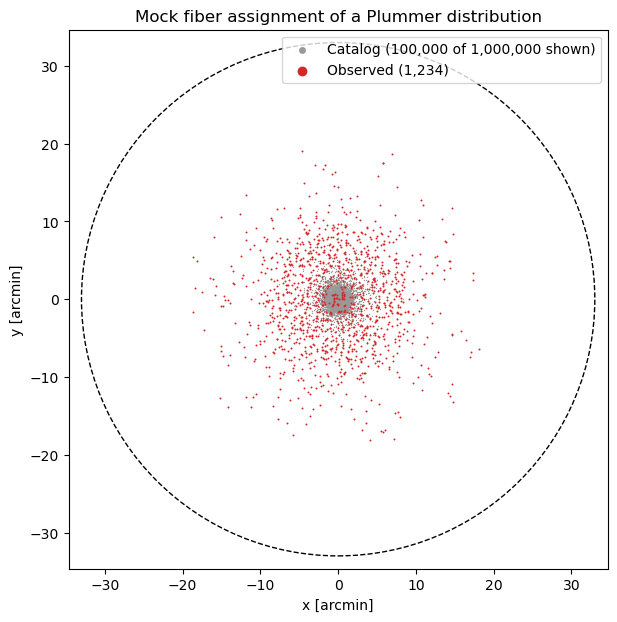

In [6]:
x, y = sample_plummer_2d(n_stars=int(1e6), rhalf=0.2, random_state=SEED)  # rhalf in arcmin
plummer = pd.DataFrame({
    'x': x,
    'y': y,
    'zmag': rng.uniform(15, 22, len(x)),
})

plummer_observed = mock_fiber_assign(
    plummer,
    n_fibers=N_FIBERS,
    fov_radius_arcmin=FOV_RADIUS_ARCMIN,
    n_grid_cells=65,
    priority_column='zmag',
    seed=SEED,
)
print(f'{len(plummer_observed):,} of {N_FIBERS:,} fibers assigned')
print(f'{np.mean(np.hypot(x, y) < 1):.0%} of the catalog lies within 1 arcmin of the centre')
plot_assignment(plummer, plummer_observed, 'Mock fiber assignment of a Plummer distribution');